<!-- # Copyright (c) 2026 takotime808 -->
# Scoring Joint Predictions: Energy and Variogram Scores

**What this tutorial covers:**

A surrogate with several outputs predicts more than a mean and a std per output. It
implies a *joint* distribution: how likely each **combination** of outputs is. When
outputs move together (lift and drag, the objectives of a Pareto front, the values of a
field at neighbouring points), a model that gets every output's own uncertainty right but
treats the outputs as independent still misjudges which combinations can happen.
Per-output metrics (RMSE, coverage, CRPS) cannot see that.

`multioutreg.metrics` has three tools for it:

| Function | What it does |
|---|---|
| `gaussian_samples(mean, cov)` | Draws samples from per-row Gaussian predictions, from a full covariance or a per-output std |
| `energy_score(Y, samples)` | The multivariate CRPS: one number for the whole joint distribution |
| `variogram_score(Y, samples, p)` | Compares the predicted and observed *differences between outputs*, so it reacts to a wrong correlation |

Both scores are *proper* (an honest forecast of the true distribution scores best in
expectation) and lower is better. This tutorial:

1. draws joint samples with `gaussian_samples`;
2. scores forecasts with one known flaw each against a known truth, to show what each
   score can and cannot see, next to per-output CRPS and the joint Gaussian log score;
3. covers the practical choices: number of samples, output scaling, the variogram's
   order `p` and pair weights;
4. compares real surrogates: an independent GP against `GaussianCopulaSurrogate`,
   `PCAOutputSurrogate` and `MultiTaskGPSurrogate`, on correlated noise and on DTLZ2;
5. ends with a guide to which score to report.

**Needs:** the core install; section 4 also uses `gpytorch` for the multi-task GP (it is
skipped without it). **Runs in:** under a minute.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import multivariate_normal, norm

from multioutreg.metrics import energy_score, gaussian_samples, variogram_score

pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

Two reference scores sit next to the joint ones throughout:

- **Per-output CRPS** (continuous ranked probability score), the usual proper score for one
  output's Gaussian prediction, averaged over outputs. Closed form for a Gaussian.
- **Joint Gaussian log score**: the negative log density of the observed vector under the
  predicted multivariate Gaussian. It sees everything, including dependence, but only
  applies when the prediction *is* Gaussian, and one badly placed point can dominate it.
  The energy and variogram scores work from samples of any distribution.

In [2]:
def crps_gaussian(mean, std, y):
    # Mean per-output CRPS of Gaussian predictions (Gneiting & Raftery 2007, closed form).
    z = (y - mean) / std
    return float(np.mean(std * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi))))


def joint_log_score(mean, cov, y):
    # Mean negative log density of each observed vector under its predicted Gaussian.
    return float(-np.mean([multivariate_normal(mean[i], cov[i], allow_singular=True).logpdf(y[i])
                           for i in range(len(y))]))


def stds(cov):
    return np.sqrt(np.diagonal(cov, axis1=1, axis2=2))

## 1. Drawing joint samples with `gaussian_samples`

Both joint scores take samples of shape `(n_rows, n_samples, n_outputs)`.
`gaussian_samples` makes them from what a surrogate returns:

- `predict(X, return_cov=True)` gives a mean `(n, m)` and a covariance `(n, m, m)` per row:
  correlated samples;
- `predict(X, return_std=True)` gives a mean and a std `(n, m)`: independent samples.

Below, one prediction with mean (0, 0), unit stds and correlation 0.8, sampled both ways.

shape: (1, 2000, 2)
sample covariance (correlated):
 [[1.01 0.79]
 [0.79 0.97]]
sample covariance (independent):
 [[ 1.   -0.03]
 [-0.03  0.99]]


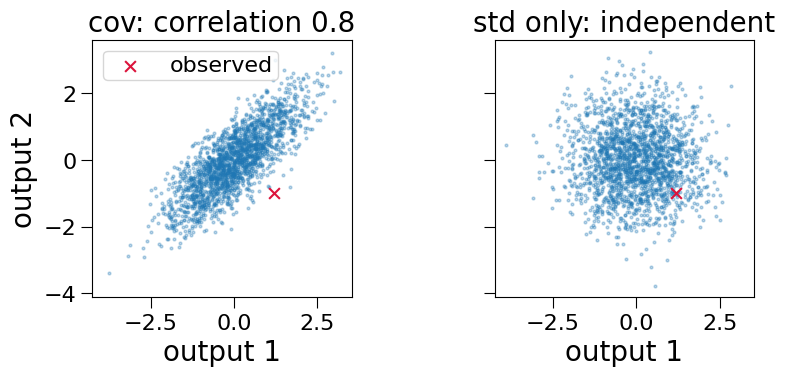

In [3]:
mean = np.zeros((1, 2))
cov = np.array([[[1.0, 0.8], [0.8, 1.0]]])          # one row, two outputs
std = np.ones((1, 2))

S_corr = gaussian_samples(mean, cov, n_samples=2000, seed=0)
S_ind = gaussian_samples(mean, std, n_samples=2000, seed=0)
print("shape:", S_corr.shape)
print("sample covariance (correlated):\n", np.cov(S_corr[0].T).round(2))
print("sample covariance (independent):\n", np.cov(S_ind[0].T).round(2))

y_obs = np.array([1.2, -1.0])  # an outcome where the outputs disagree
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, S, title in [(axes[0], S_corr, "cov: correlation 0.8"), (axes[1], S_ind, "std only: independent")]:
    ax.scatter(*S[0].T, s=4, alpha=0.3)
    ax.scatter(*y_obs, color="crimson", s=60, marker="x", label="observed")
    ax.set_title(title); ax.set_xlabel("output 1"); ax.set_aspect("equal")
axes[0].set_ylabel("output 2"); axes[0].legend(loc="upper left")
plt.tight_layout(); plt.show()

The two clouds have identical marginals: each output alone is N(0, 1) in both. Only the
joint shape differs. The observed point, with one output high and the other low, sits in
the empty corner of the correlated cloud. A per-output score rates the two forecasts of
this point equally; a joint score does not.

`gaussian_samples` takes the covariance's square root by eigen-decomposition rather than
Cholesky, so a singular covariance (perfectly correlated outputs, or a
`PCAOutputSurrogate` that keeps fewer components than outputs) still works:

In [4]:
singular = np.array([[[1.0, 1.0], [1.0, 1.0]]])     # outputs identical
S = gaussian_samples(np.zeros((1, 2)), singular, n_samples=5, seed=0)
print(S[0].round(3))  # both columns equal

[[-0.132 -0.132]
 [ 0.105  0.105]
 [ 0.362  0.362]
 [ 0.947  0.947]
 [-1.265 -1.265]]


## 2. What each score can and cannot see

To know which answer is right, generate the truth ourselves: 200 rows, two outputs whose
noise has correlation 0.8, and the true mean known for every row. Then score seven
forecasts. The first is the truth itself; each other one has exactly one flaw.

In [5]:
n, rho = 200, 0.8
mu = rng.normal(size=(n, 2))                                        # true means
Y = mu + rng.multivariate_normal([0, 0], [[1, rho], [rho, 1]], size=n)


def covs(r, scale=1.0):
    return np.broadcast_to(scale**2 * np.array([[1.0, r], [r, 1.0]]), (n, 2, 2)).copy()


forecasts = {
    "perfect": (mu, covs(rho)),
    "independent (corr 0)": (mu, covs(0.0)),
    "wrong sign (corr -0.8)": (mu, covs(-rho)),
    "bias on output 1 (+0.5)": (mu + [0.5, 0.0], covs(rho)),
    "same shift on both (+0.5)": (mu + 0.5, covs(rho)),
    "too wide (std x2)": (mu, covs(rho, 2.0)),
    "too narrow (std x0.5)": (mu, covs(rho, 0.5)),
}

rows = {}
for name, (m, c) in forecasts.items():
    S = gaussian_samples(m, c, n_samples=200, seed=1)
    rows[name] = {
        "per-output CRPS": crps_gaussian(m, stds(c), Y),
        "energy score": energy_score(Y, S),
        "variogram score": variogram_score(Y, S, p=0.5),
        "joint log score": joint_log_score(m, c, Y),
    }
scores = pd.DataFrame(rows).T
scores

,per-output CRPS,energy score,variogram score,joint log score
perfect,0.5766,0.8612,0.1571,2.3381
independent (corr 0),0.5766,0.8911,0.2263,2.8816
wrong sign (corr -0.8),0.5766,0.9571,0.3256,6.1146
bias on output 1 (+0.5),0.6079,0.9217,0.2210,2.6839
same shift on both (+0.5),0.6370,0.9406,0.1571,2.4534
too wide (std x2),0.6632,0.9936,0.1942,2.9661
too narrow (std x0.5),0.6291,0.9387,0.1685,3.9848


Raw values are on different scales, so compare each column to the perfect forecast:

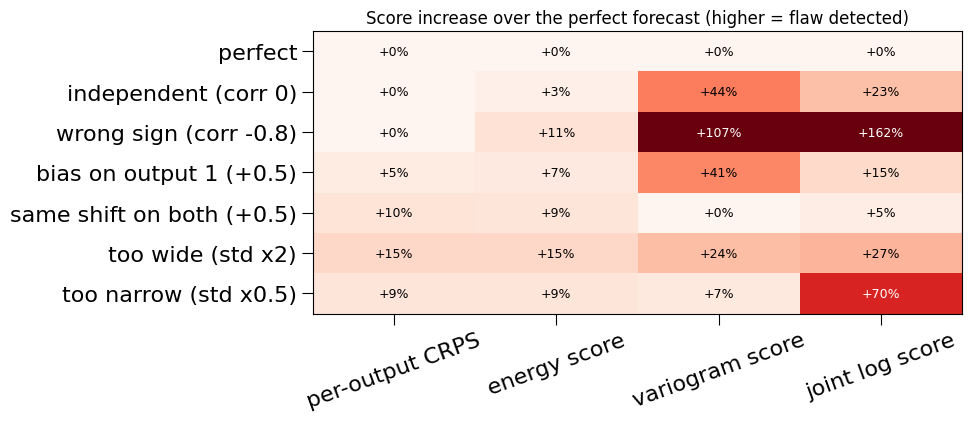

In [6]:
rel = 100 * (scores / scores.loc["perfect"] - 1)
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(rel.values, cmap="Reds", vmin=0, vmax=100, aspect="auto", origin="upper")
ax.set_xticks(range(rel.shape[1]), rel.columns, rotation=20)
ax.set_yticks(range(rel.shape[0]), rel.index)
for i in range(rel.shape[0]):
    for j in range(rel.shape[1]):
        v = rel.values[i, j]
        v = 0.0 if abs(v) < 0.5 else v
        ax.text(j, i, f"{v:+.0f}%", ha="center", va="center", fontsize=9,
                color="white" if v > 60 else "black")
ax.set_title("Score increase over the perfect forecast (higher = flaw detected)", fontsize=12)
plt.tight_layout(); plt.show()

How to read the table, row by row:

- **Independent and wrong-sign forecasts** have the right marginals, so per-output CRPS is
  *exactly* unchanged: it cannot see dependence. The energy score notices, but only
  weakly (a few percent for "independent"). The variogram and joint log scores react strongly.
- **Bias on one output** is seen by every score.
- **The same shift on every output** is the variogram score's blind spot: it looks only
  at differences *between* outputs, which a common shift leaves unchanged, so its value is
  identical to the perfect forecast's. Always report it next to a score that sees the means.
- **Too wide / too narrow**: all scores punish miscalibrated spread, the log score most
  harshly when intervals are too narrow.

A forecast's assumed correlation can also be swept directly. The truth's correlation is 0.8;
a proper score should be lowest there:

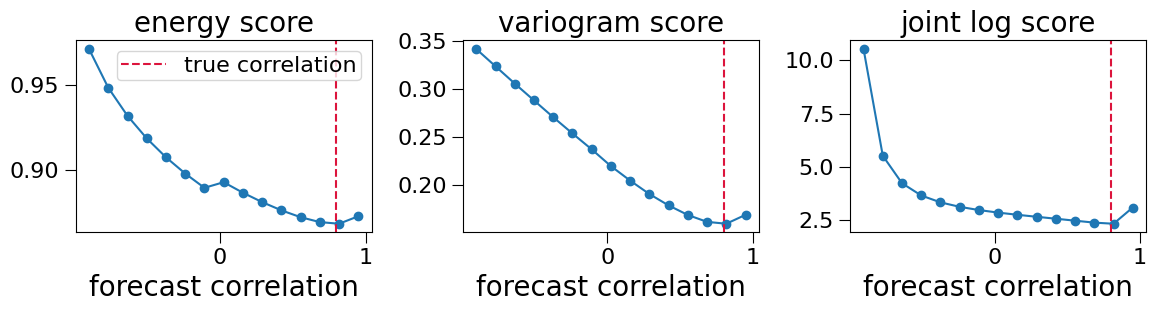

In [7]:
grid = np.linspace(-0.9, 0.95, 15)
sweep = {"energy score": [], "variogram score": [], "joint log score": []}
for r in grid:
    S = gaussian_samples(mu, covs(r), n_samples=150, seed=2)
    sweep["energy score"].append(energy_score(Y, S))
    sweep["variogram score"].append(variogram_score(Y, S))
    sweep["joint log score"].append(joint_log_score(mu, covs(r), Y))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (name, vals) in zip(axes, sweep.items()):
    ax.plot(grid, vals, marker="o")
    ax.axvline(rho, color="crimson", ls="--", label="true correlation")
    ax.set_title(name); ax.set_xlabel("forecast correlation")
axes[0].legend()
plt.tight_layout(); plt.show()

All three bottom out near the true correlation, which is what *proper* means in practice.
The energy score's curve is shallow (a wrong correlation costs it little), the variogram
score's is steep. With noisy data the energy score may not separate two models that
differ only in their dependence; the variogram score usually will.

**One more identity.** With a single output, the energy score *is* the CRPS. Checked
numerically against the closed form (the small gap is Monte Carlo error; see section 3):

In [8]:
S1 = gaussian_samples(mu[:, :1], np.ones((n, 1)), n_samples=400, seed=0)
print(f"energy score, 1 output: {energy_score(Y[:, :1], S1):.4f}")
print(f"closed-form CRPS:       {crps_gaussian(mu[:, :1], np.ones((n, 1)), Y[:, :1]):.4f}")

energy score, 1 output: 0.5769
closed-form CRPS:       0.5715


## 3. Practical choices

### How many samples?

Both scores are estimated from samples, so they carry Monte Carlo noise. The energy score
also has a small-sample **bias**: its second term averages distances between pairs of
samples, including each sample with itself (distance 0), which makes it too high when
`n_samples` is small. Cost grows with the square of `n_samples`, because the energy
score compares every pair of samples: it builds an `(n_rows, n_samples, n_samples,
n_outputs)` array, so 1,000 rows with 1,000 samples and 3 outputs would need about 24 GB.
Score in batches of rows if needed.

In [9]:
import time

rows = []
for S_n in (10, 25, 50, 100, 200):
    t0 = time.perf_counter()
    vals = [energy_score(Y, gaussian_samples(mu, covs(rho), S_n, seed=k)) for k in range(5)]
    rows.append({"n_samples": S_n, "mean over 5 seeds": np.mean(vals), "std over seeds": np.std(vals),
                 "seconds per score": (time.perf_counter() - t0) / 5})
pd.DataFrame(rows).set_index("n_samples")

,mean over 5 seeds,std over seeds,seconds per score
n_samples,,,
10,0.9420,0.0278,0.0022
25,0.8984,0.0094,0.0093
50,0.8810,0.0088,0.0227
100,0.8620,0.0078,0.1038
200,0.8624,0.0029,0.4494


With few samples the energy score is biased upward and varies between seeds; from a
hundred or two samples on, both effects are small next to the differences in section 2.
**Fix the seed** (`seed=...`) when comparing models, so they are scored on the same random
draws and the comparison is not just noise.

### Put the outputs on one scale

Both scores add up distances *across* outputs, so an output measured in large units drowns
out the others. Below, the same forecasts are scored with output 2 multiplied by 1000, as
if it were in millimetres while output 1 is in metres:

In [10]:
scale = np.array([1.0, 1000.0])
rows = {}
for name in ["perfect", "independent (corr 0)", "bias on output 1 (+0.5)"]:
    m, c = forecasts[name]
    S_raw = gaussian_samples(m * scale, c * np.outer(scale, scale), 200, seed=1)
    S_std = S_raw / scale                               # standardized back
    rows[name] = {"energy, raw units": energy_score(Y * scale, S_raw),
                  "energy, standardized": energy_score(Y, S_std)}
pd.DataFrame(rows).T

,"energy, raw units","energy, standardized"
perfect,582.9098,0.8611
independent (corr 0),582.9106,0.8911
bias on output 1 (+0.5),582.9104,0.9226


In raw units the forecast with a bias on output 1 scores almost the same as the perfect
one, because output 1 is invisible next to output 2's thousands. Divide each output by a
fixed scale (e.g. its training-set std) before scoring, and use the *same* scale for every
model you compare.

### The variogram order `p` and pair weights

`p` sets how pairwise differences are compared. `p = 0.5` (the default) is the usual choice:
larger `p` weighs large differences more and becomes sensitive to outliers and heavy tails.
Below, the perfect and independent forecasts are scored on clean data and on the same data
with a few large outliers:

In [11]:
Y_out = Y.copy()
Y_out[:5, 0] += 8.0                                    # five gross errors in output 1
rows = []
for p in (0.5, 1.0, 2.0):
    for label, data in [("clean", Y), ("5 outliers", Y_out)]:
        good = variogram_score(data, gaussian_samples(mu, covs(rho), 200, seed=1), p=p)
        indep = variogram_score(data, gaussian_samples(mu, covs(0.0), 200, seed=1), p=p)
        rows.append({"p": p, "data": label, "perfect": good, "independent": indep,
                     "independent / perfect": indep / good})
pd.DataFrame(rows).set_index(["p", "data"])

perfect  independent  independent / perfect
p   data                                                    
0.5 clean         0.1571       0.2263                 1.4409
    5 outliers    0.3504       0.3680                 1.0505
1.0 clean         0.5859       0.9204                 1.5710
    5 outliers    2.9495       2.9137                 0.9879
2.0 clean         6.7766      11.6452                 1.7184
    5 outliers  171.5248     167.2928                 0.9753

On clean data every `p` ranks the perfect forecast first, and larger `p` separates the
two forecasts a little more. Five gross errors change that. They dominate the score: at
`p = 0.5` the independent forecast is now only about 5% worse than the perfect one, and at
`p = 1` and `p = 2` the order **flips** and the wrong forecast scores better. `p = 0.5` is
the only order here that still ranks them correctly. So keep `p = 0.5`, and look for
outliers (or gross errors in the data) before trusting any variogram comparison.

`weights` (an `(m, m)` matrix) sets how much each pair of outputs counts. Use it to score
only the pairs you care about, or to down-weight pairs that are far apart (e.g. distant
points of a field, where little correlation is expected):

In [12]:
m3 = 3
W_only_01 = np.zeros((m3, m3)); W_only_01[0, 1] = W_only_01[1, 0] = 1.0   # just outputs 0 and 1
mean3 = np.zeros((4, m3)); y3 = rng.normal(size=(4, m3))
S3 = gaussian_samples(mean3, np.ones((4, m3)), 100, seed=0)
print("all pairs:         ", round(variogram_score(y3, S3), 4))
print("only pair (0, 1):  ", round(variogram_score(y3, S3, weights=W_only_01), 4))

all pairs:          0.5329
only pair (0, 1):   0.2891


## 4. Comparing surrogates

Now the question these scores exist for: **does a model that represents dependence between
outputs predict better than one that does not?** Four candidates, all built on Gaussian
processes so that only the dependence model differs:

| Model | How outputs are linked |
|---|---|
| `GaussianProcessSurrogate` | Not at all: one GP per output, independent errors |
| `GaussianCopulaSurrogate` | Same GPs, plus a correlation of their errors estimated from out-of-fold residuals |
| `PCAOutputSurrogate` | GPs on the principal components of the outputs, mapped back with the full covariance |
| `MultiTaskGPSurrogate` | One GP over all outputs with a learned output covariance (ICM kernel); needs `gpytorch` |

Every model is scored on outputs standardized by the training std, with the same seed for
the samples.

In [13]:
from multioutreg.surrogates import (
    GaussianCopulaSurrogate,
    GaussianProcessSurrogate,
    PCAOutputSurrogate,
)
from multioutreg.surrogates.multitask_gp_gpytorch import _GPYTORCH_AVAILABLE, MultiTaskGPSurrogate


def candidates(n_outputs):
    models = {
        "GP (independent)": GaussianProcessSurrogate(),
        "Gaussian copula + GP": GaussianCopulaSurrogate(cv=5, random_state=0),
        "PCA output + GP": PCAOutputSurrogate(n_components=n_outputs),
    }
    if _GPYTORCH_AVAILABLE:
        models["Multi-task GP (ICM)"] = MultiTaskGPSurrogate(random_state=0)
    return models


def predict_joint(model, X, n_outputs):
    # Mean and per-row covariance; models without return_cov get a diagonal one.
    try:
        mean, cov = model.predict(X, return_cov=True)
    except TypeError:
        mean, std = model.predict(X, return_std=True)
        cov = np.asarray(std)[:, :, None] ** 2 * np.eye(n_outputs)
    return np.asarray(mean), np.asarray(cov)


def compare(X_tr, Y_tr, X_te, Y_te):
    m_out = Y_tr.shape[1]
    sc = Y_tr.std(axis=0)                                  # one scale for every model
    rows = {}
    for name, model in candidates(m_out).items():
        model.fit(X_tr, Y_tr)
        mean, cov = predict_joint(model, X_te, m_out)
        ms, ys, cs = mean / sc, Y_te / sc, cov / np.outer(sc, sc)
        S = gaussian_samples(ms, cs, n_samples=200, seed=0)
        corr = cs[:, 0, 1] / np.sqrt(cs[:, 0, 0] * cs[:, 1, 1])
        rows[name] = {
            "RMSE": float(np.sqrt(np.mean((ms - ys) ** 2))),
            "per-output CRPS": crps_gaussian(ms, stds(cs), ys),
            "energy score": energy_score(ys, S),
            "variogram score": variogram_score(ys, S),
            "joint log score": joint_log_score(ms, cs, ys),
            "predicted corr(0, 1)": float(np.mean(corr)),
        }
    return pd.DataFrame(rows).T

### 4a. Outputs that share their noise

Two outputs that depend on different inputs but share most of their measurement noise
(noise correlation 0.85), as when two quantities come from the same noisy experiment run:

In [14]:
def shared_noise_data(n, seed):
    r = np.random.default_rng(seed)
    X = r.uniform(0, 1, size=(n, 2))
    e, u = r.normal(size=n), r.normal(size=(n, 2))
    noise = 0.3 * (0.92 * e[:, None] + 0.39 * u)           # correlation 0.92^2 / (0.92^2 + 0.39^2) = 0.85
    Y = np.c_[np.sin(6 * X[:, 0]), np.cos(5 * X[:, 1]) + X[:, 0]] + noise
    return X, Y


X_tr, Y_tr = shared_noise_data(120, seed=0)
X_te, Y_te = shared_noise_data(300, seed=1)
shared = compare(X_tr, Y_tr, X_te, Y_te)
shared

,RMSE,per-output CRPS,energy score,variogram score,joint log score,"predicted corr(0, 1)"
GP (independent),0.4192,0.2347,0.3627,0.0508,1.0863,0.0000
Gaussian copula + GP,0.4192,0.2347,0.3500,0.0367,0.5123,0.8122
PCA output + GP,0.6600,0.3732,0.5422,0.0344,1.0115,0.9408
Multi-task GP (ICM),0.4187,0.2347,0.3604,0.0517,1.0816,0.0064


What the scores say:

- **Copula vs independent GP.** Identical RMSE and per-output CRPS: the copula keeps the
  GP's means and stds and only adds the correlation, which it estimates close to the true
  0.85. Per-output metrics therefore rate the two models as equal. The joint scores do not:
  the variogram score drops by about a quarter and the joint log score roughly halves. The
  energy score improves too, but only by a few percent, the shallow curve from section 2.
- **Multi-task GP.** It predicts a correlation near zero. The ICM kernel correlates the
  outputs' *underlying functions*, while the noise model is independent per output. Here
  the two functions are unrelated and only the noise is shared, so it has nothing to learn.
- **PCA output.** The best variogram score, but clearly worse means (higher RMSE and CRPS),
  because each principal component mixes two unrelated functions. This is the variogram
  score's blind spot from section 2 in a real model: always read it next to a marginal
  score.

### 4b. DTLZ2: dependence in the function, not the noise

DTLZ2 is a 3-objective benchmark whose outputs are strongly dependent through the function
itself (all three are scaled by a common factor). There is no noise, so the models' errors
are their only randomness. 60 training rows:

In [15]:
from multioutreg.active.benchmarks import get_benchmark

bench = get_benchmark("dtlz2")
f = bench.functions["hi"]
X_tr = bench.sample(60, "lhs", seed=0)
X_te = bench.sample(150, "random", seed=1)
dtlz = compare(X_tr, f(X_tr), X_te, f(X_te))
dtlz

,RMSE,per-output CRPS,energy score,variogram score,joint log score,"predicted corr(0, 1)"
GP (independent),0.2577,0.1405,0.2793,0.2384,0.6812,0.0000
Gaussian copula + GP,0.2577,0.1405,0.2793,0.2388,1.2216,-0.1418
PCA output + GP,0.2434,0.1294,0.2598,0.2282,-0.3045,-0.0352
Multi-task GP (ICM),0.2286,0.1214,0.2502,0.1181,0.7182,0.2837


Here the picture is different:

- **The multi-task GP** wins on RMSE, CRPS, energy and variogram score. Sharing information
  between outputs helps the *means*, and the learned output covariance halves the
  variogram score.
- **The joint log score disagrees.** It ranks the PCA model first and puts the multi-task
  GP slightly behind the independent GP. The log score punishes any point that falls far
  outside a narrow predicted density, so a model with tight, slightly overconfident
  intervals can lose on it while winning everywhere else. When the scores disagree like
  this, look at calibration per output (coverage, or the std recalibration wrapper) before
  picking a model on any single number.
- **The copula does not help, and its log score is worse.** Its correlation comes from the
  GP's out-of-fold residuals, and with 60 rows those are noisy: compare the residual
  correlations it learned with the ones on the test set below. One pair comes out with the
  wrong sign, the flaw that cost the most in section 2. `shrinkage` (towards independence)
  limits the damage when there are few rows per output.

In [16]:
gp = GaussianProcessSurrogate().fit(X_tr, f(X_tr))
m, s = gp.predict(X_te, return_std=True)
pairs = ["(0, 1)", "(0, 2)", "(1, 2)"]
iu = np.triu_indices(3, 1)
test_corr = np.corrcoef(((f(X_te) - m) / s).T)[iu]
learned = {f"copula, shrinkage={sh}": GaussianCopulaSurrogate(cv=5, shrinkage=sh, random_state=0)
           .fit(X_tr, f(X_tr)).correlation_[iu] for sh in (0.0, 0.5)}
pd.DataFrame({"test-set residual corr": test_corr, **learned}, index=pairs)

,test-set residual corr,"copula, shrinkage=0.0","copula, shrinkage=0.5"
"(0, 1)",-0.3364,-0.1418,-0.0709
"(0, 2)",-0.2079,-0.2068,-0.1034
"(1, 2)",-0.3464,0.3284,0.1642


So the joint scores did their job in both cases: they showed when adding dependence helped
(4a) and when it did not (4b), which per-output metrics alone could not.

## 5. Which score to report

| Question | Score |
|---|---|
| Are the means right? | RMSE / MAE |
| Is each output's uncertainty right? | per-output CRPS (or coverage) |
| Is the joint distribution right, as one number? | **energy score**: proper and works for any samples, but weak on dependence |
| Is the dependence between outputs right? | **variogram score** (`p = 0.5`): strong on dependence, blind to shifts shared by all outputs |
| Gaussian predictions, and you want the sharpest test? | joint Gaussian log score: sees everything, but sensitive to a few bad points |

Practical rules from this tutorial:

1. Report a joint score **next to** a marginal one, never alone.
2. Standardize outputs with one fixed scale (e.g. training std) shared by all models.
3. Fix the sampling `seed` and use a hundred or more samples; watch memory, which grows
   with `n_rows × n_samples² × n_outputs`.
4. A model that adds dependence (copula, PCA output, multi-task GP) is worth it only if
   the joint scores improve *without* the marginal ones getting worse.

**Related pages:** [Multi-Objective Metrics](../multiobjective_metrics.md) (the regrets
and the score definitions), [Integrated Surrogate Models](../integrated_surrogates.md)
(all surrogates), and [Multi-Output Surrogates, Start to Finish](multi_output_surrogates.ipynb)
(per-output uncertainty and conformal intervals).